# Exercise 4 · What the atmosphere does to the pixels
**ICAT3370 Foundations of Space Data and EO Systems** · 20 October 2026

**In Exercise 2** we downloaded one Sentinel-2 image of Vaasa, clipped it and read the first measurements. We used a Level 2A product. Today we find out how  L2A processing effected our measurements by comparing it with the Level 1C product of the same scene.

**Contents**
1. Open two products of the same moment and see what is different
2. Turn the Level 1C numbers into reflectance and compare them with Level 2A
3. Correct the atmosphere ourselves with the simplest method
4. See what ESA's processor believed about the sky that day
5. Map turbidity on each version and see how much the correction matters

**Instructions.** Run a cell with **Shift + Enter**. You do not need to write anything in this notebook.

***
## 0 · Did you notice?

In Exercise 2 we used a product whose name started with `S2B_MSIL2A`. In Exercise 1 the first part of the name was `S2B_MSIL1C`.

:::{admonition} Discussion
Both products are from the same satellite and the same moment. Why would ESA publish the same view of Vaasa twice, and which one would you trust to measure how muddy the water is?
:::

***
## 1 · Two products of the same scene

Sentinel-2 images come in two main levels. A **Level 1C** product holds the light that reached the satellite, measured as **top of atmosphere** reflectance. The light has passed through the whole atmosphere twice, down from the sun and up to the satellite, and the numbers contain everything the air added or took away. A **Level 2A** product is made from the Level 1C product by a processor called Sen2Cor. It tries to remove the effect of the atmosphere and delivers **bottom of atmosphere** reflectance, which is the reflectance at the ground or at the water surface.

Both products for the Sentinel-2B pass of 21 June 2026 were downloaded beforehand. The next cell lists what is in the data folder.

In [1]:
import os

data_folder = "/scratch/project_2020353/data/exercise_4"    # where the course data is kept on CSC

products = sorted(name for name in os.listdir(data_folder) if name.endswith(".SAFE"))

for product in products:
    print(product)

S2B_MSIL1C_20260621T101019_N0512_R022_T34VER_20260621T134515.SAFE
S2B_MSIL2A_20260621T101019_N0512_R022_T34VER_20260621T140048.SAFE


:::{admonition} Discussion
Compare the two names part by part. Which parts are the same and which are different? Why do the last parts, the processing times, differ by about 15 minutes?
:::

The next cell cuts each name at the underscores and puts the parts into a table.

In [2]:
import pandas as pd

rows = []
for product in products:
    part = product.replace(".SAFE", "").split("_")
    rows.append({
        "satellite": part[0],
        "level": part[1],
        "sensing start": part[2],
        "baseline": part[3],
        "orbit": part[4],
        "tile": part[5],
        "processed": part[6],
    })

pd.DataFrame(rows).T

,0,1
satellite,S2B,S2B
level,MSIL1C,MSIL2A
sensing start,20260621T101019,20260621T101019
baseline,N0512,N0512
orbit,R022,R022
tile,T34VER,T34VER
processed,20260621T134515,20260621T140048


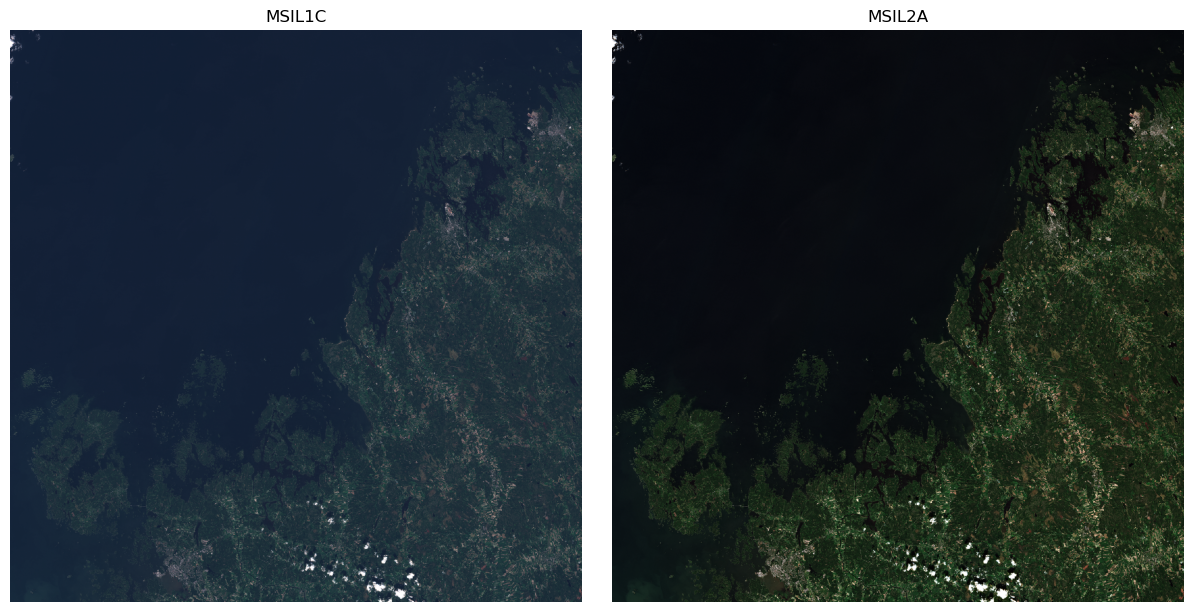

In [39]:
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt

def quick_look(product):
    folder = os.path.join(data_folder, product)
    granule = glob.glob(f"{folder}/GRANULE/*")[0]
    file = (glob.glob(f"{granule}/IMG_DATA/*TCI*.jp2") or glob.glob(f"{granule}/IMG_DATA/R10m/*TCI*.jp2"))[0]
    with rasterio.open(file) as src:
        return src.read(out_shape=(3, src.height // 10, src.width // 10)).transpose(1, 2, 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for axis, product in zip(axes, products):
    axis.imshow(quick_look(product))
    axis.set_title(product.split("_")[1])
    axis.set_axis_off()
plt.show()

def quick_look(product):
    folder = os.path.join(data_folder, product)
    granule = glob.glob(f"{folder}/GRANULE/*")[0]
    file = (glob.glob(f"{granule}/IMG_DATA/*TCI*.jp2") or glob.glob(f"{granule}/IMG_DATA/R10m/*TCI*.jp2"))[0]
    with rasterio.open(file) as src:
        return src.read(out_shape=(3, src.height // 10, src.width // 10)).transpose(1, 2, 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for axis, product in zip(axes, products):
    axis.imshow(quick_look(product))
    axis.set_title(product.split("_")[1])
    axis.set_axis_off()
plt.show()

:::{admonition} Discussion
Which row would you expect to change if we ordered the same view from another day? And which row tells us which of the two products was made first?
:::

### What is inside the folders

Both products are folders with the ending `.SAFE`. The next cell lists the first level of each folder, and then the folder that holds the band files.

In [24]:
from pathlib import Path

for product in products:
    folder = Path(data_folder) / product
    granule = next(folder.glob("GRANULE/*"))
    print(product)
    print("   Top of the product", *sorted(p.name for p in folder.iterdir()), sep="\n      ")
    print("   Band folder", *sorted(p.name for p in (granule / "IMG_DATA").iterdir()), sep="\n      ")
    print()

S2B_MSIL1C_20260621T101019_N0512_R022_T34VER_20260621T134515.SAFE
   Top of the product
      DATASTRIP
      GRANULE
      HTML
      INSPIRE.xml
      MTD_MSIL1C.xml
      S2B_MSIL1C_20260621T101019_N0512_R022_T34VER_20260621T134515-ql.jpg
      manifest.safe
      rep_info
   Band folder
      T34VER_20260621T101019_B01.jp2
      T34VER_20260621T101019_B02.jp2
      T34VER_20260621T101019_B03.jp2
      T34VER_20260621T101019_B04.jp2
      T34VER_20260621T101019_B05.jp2
      T34VER_20260621T101019_B06.jp2
      T34VER_20260621T101019_B07.jp2
      T34VER_20260621T101019_B08.jp2
      T34VER_20260621T101019_B09.jp2
      T34VER_20260621T101019_B10.jp2
      T34VER_20260621T101019_B11.jp2
      T34VER_20260621T101019_B12.jp2
      T34VER_20260621T101019_B8A.jp2
      T34VER_20260621T101019_TCI.jp2

S2B_MSIL2A_20260621T101019_N0512_R022_T34VER_20260621T140048.SAFE
   Top of the product
      DATASTRIP
      GRANULE
      HTML
      INSPIRE.xml
      MTD_MSIL2A.xml
      S2B_MSIL2A_2026

:::{admonition} Discussion
Where are the band files of each product? Why does the Level 2A product have the folders R10m, R20m and R60m, and what does that tell you about the Level 1C bands?
:::

### What the metadata says

Every product carries an XML file with its description. The Level 1C file is called `MTD_MSIL1C.xml` and the Level 2A file `MTD_MSIL2A.xml`. The next cell reads six fields from each. The last two are the numbers that turn the stored whole numbers back into reflectance, the scale and the offset. In Exercise 2 we used them for Level 2A.

In [27]:
import re

def first(path, tag):
    text = open(path).read()
    return re.search(f"<{tag}[^>]*>([^<]*)</{tag}>", text).group(1)

fields = {}
for product in products:
    folder = os.path.join(data_folder, product)
    xml = glob.glob(f"{folder}/MTD_MSI*.xml")[0]
    if "MSIL1C" in product:
        scale, offset = "QUANTIFICATION_VALUE", "RADIO_ADD_OFFSET"
    else:
        scale, offset = "BOA_QUANTIFICATION_VALUE", "BOA_ADD_OFFSET"
    fields[product.split("_")[1]] = {
        "Processing level": first(xml, "PROCESSING_LEVEL"),
        "Processing baseline": first(xml, "PROCESSING_BASELINE"),
        "Sensing start": first(xml, "PRODUCT_START_TIME"),
        "Generated": first(xml, "GENERATION_TIME"),
        "Scale": first(xml, scale),
        "Scale field in the file": scale,
        "Offset": first(xml, offset),
        "Offset field in the file": offset,
    }

table = pd.DataFrame(fields)
table

,MSIL1C,MSIL2A
Processing level,Level-1C,Level-2A
Processing baseline,05.12,05.12
Sensing start,2026-06-21T10:10:19.024Z,2026-06-21T10:10:19.024Z
Generated,2026-06-21T13:45:15.000000Z,2026-06-21T14:00:48.000000Z
Scale,10000,10000
Scale field in the file,QUANTIFICATION_VALUE,BOA_QUANTIFICATION_VALUE
Offset,-1000,-1000
Offset field in the file,RADIO_ADD_OFFSET,BOA_ADD_OFFSET


:::{admonition} Discussion
Which fields are identical in the two products and which differ? The two columns use different names for the offset in the file. What do the words RADIO and BOA tell you about what the number belongs to?
:::

We now have the same view of Vaasa twice. Next we turn the Level 1C numbers into reflectance and place them next to Level 2A, one pixel at a time.

***
## 2 · Level 1C against Level 2A, pixel by pixel

### The area and the bands

We need the Vaasa polygon again. The next cell fetches the municipality files in the same way as in Exercise 2 and picks Vaasa.

In [29]:
import urllib.request
import geopandas as gpd

base = "https://nic.funet.fi/index/geodata/mml/hallintorajat_10k/2025/SuomenKuntajako_2025_10k"
os.makedirs("data/aoi", exist_ok=True)
for ext in ["shp", "shx", "dbf", "prj"]:
    urllib.request.urlretrieve(f"{base}.{ext}", f"data/aoi/SuomenKuntajako_2025_10k.{ext}")

municipalities = gpd.read_file("data/aoi/SuomenKuntajako_2025_10k.shp")
vaasa = municipalities[municipalities["NAMEFIN"] == "Vaasa"]

For the study of turbidity we need four bands, blue (B02), green (B03), red (B04) and the near infrared (B08). All four have a pixel size of 10 m in both products. The function in the next cell opens one band of one product, clips it to Vaasa and turns the stored whole numbers into reflectance. It reads the scale and the offset from the metadata file of the product it is working on, so the same function serves both levels.

$$\text{reflectance} = \frac{\text{DN} + \text{offset}}{\text{scale}}$$

The pixels outside the polygon hold the number 0. We set them to missing values so they do not take part in anything we calculate.

In [32]:
import numpy as np
import rasterio
from rasterio.mask import mask

def clipped_reflectance(product, band):
    folder = os.path.join(data_folder, product)
    granule = glob.glob(f"{folder}/GRANULE/*")[0]
    xml = glob.glob(f"{folder}/MTD_MSI*.xml")[0]

    if "MSIL1C" in product:
        file = glob.glob(f"{granule}/IMG_DATA/*_{band}.jp2")[0]
        scale = float(first(xml, "QUANTIFICATION_VALUE"))
        offset = float(first(xml, "RADIO_ADD_OFFSET"))
    else:
        file = glob.glob(f"{granule}/IMG_DATA/R10m/*_{band}_10m.jp2")[0]
        scale = float(first(xml, "BOA_QUANTIFICATION_VALUE"))
        offset = float(first(xml, "BOA_ADD_OFFSET"))

    with rasterio.open(file) as src:
        shape = vaasa.to_crs(src.crs).make_valid().iloc[0]
        dn, _ = mask(src, [shape], crop=True)

    reflectance = (dn[0].astype("float32") + offset) / scale
    reflectance[dn[0] == 0] = np.nan
    return reflectance

level_1c, level_2a = products
bands = ["B02", "B03", "B04", "B08"]

l1c = {band: clipped_reflectance(level_1c, band) for band in bands}
l2a = {band: clipped_reflectance(level_2a, band) for band in bands}

print("Shape of the clipped array", l1c["B04"].shape, l2a["B04"].shape)

Shape of the clipped array (1537, 6140) (1537, 6140)


:::{admonition} Discussion
Both arrays have the same shape. Why was that to be expected, and what would it have meant if they were different? What do you think the missing values around the polygon do to a mean?
:::

### Sea, Plume and City

These are the three places from Exercise 2, the open sea west of Vaasa, the river plume and the city centre. At each place we take a block of 5 by 5 pixels, which is 50 m by 50 m on the ground. Before we calculate anything, the next cell shows where the blocks are. The first picture shows the whole clipped area in true colour, the second shows a close up of each block in a yellow square.

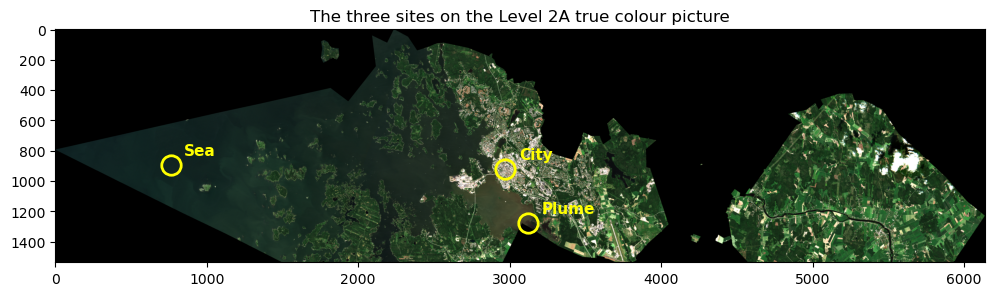

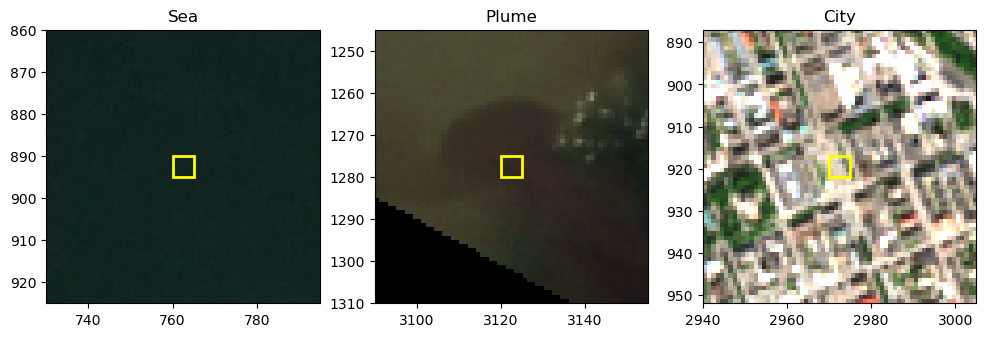

In [34]:
sites = {"Sea": (760, 890), "Plume": (3120, 1275), "City": (2970, 917)}

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

rgb = np.dstack([l2a["B04"], l2a["B03"], l2a["B02"]])
rgb = np.nan_to_num(rgb / 0.15).clip(0, 1)

plt.figure(figsize=(12, 4))
plt.imshow(rgb)
for site, (column, row) in sites.items():
    plt.plot(column + 2, row + 2, "o", markersize=14, markerfacecolor="none", markeredgecolor="yellow", markeredgewidth=2)
    plt.text(column + 90, row - 60, site, color="yellow", fontsize=11, fontweight="bold")
plt.title("The three sites on the Level 2A true colour picture")
plt.show()

plt.figure(figsize=(12, 4))
for number, (site, (column, row)) in enumerate(sites.items(), start=1):
    plt.subplot(1, 3, number)
    window = (slice(row - 30, row + 35), slice(column - 30, column + 35))
    plt.imshow(rgb[window], extent=(column - 30, column + 35, row + 35, row - 30), interpolation="nearest")
    plt.gca().add_patch(Rectangle((column, row), 5, 5, fill=False, edgecolor="yellow", linewidth=2))
    plt.title(f"{site}")
plt.show()

Now the numbers. For each block the next cell calculates the mean reflectance in each band, once from the Level 1C product and once from the Level 2A product.

In [36]:
names = {"B02": "Blue", "B03": "Green", "B04": "Red", "B08": "Near infrared"}

def block_mean(array, site):
    column, row = sites[site]
    return float(np.nanmean(array[row:row + 5, column:column + 5]))

rows = []
for site in sites:
    for band in bands:
        top = block_mean(l1c[band], site)
        bottom = block_mean(l2a[band], site)
        rows.append({
            "Site": site,
            "Band": names[band],
            "Level 1C (%)": round(top * 100, 1),
            "Level 2A (%)": round(bottom * 100, 1),
            "Difference (%)": round((top - bottom) * 100, 1),
            "Share from the atmosphere (%)": round((top - bottom) / top * 100),
        })

pd.DataFrame(rows)

,Site,Band,Level 1C (%),Level 2A (%),Difference (%),Share from the atmosphere (%)
0,Sea,Blue,7.8,1.9,5.9,75
1,Sea,Green,5.4,2.1,3.3,61
2,Sea,Red,2.9,1.0,1.9,66
3,Sea,Near infrared,1.4,0.5,0.9,63
4,Plume,Blue,7.9,2.0,6.0,75
5,Plume,Green,5.8,2.4,3.3,58
6,Plume,Red,4.7,3.1,1.7,35
7,Plume,Near infrared,2.8,1.8,1.0,35
8,City,Blue,13.8,10.0,3.9,28
9,City,Green,12.5,11.3,1.2,9


:::{admonition} Discussion
Look at the sea first. Which band has the largest difference between the two levels, and what share of the light that the satellite measured never came from the water? Then compare with the city. Why is the share so much smaller there? Find the one cell where the difference is negative and say what it means, that Level 2A is brighter than Level 1C.
:::

The next cell draws the same numbers as spectra. Each line is one site. The solid lines are Level 2A and the dashed lines are Level 1C.

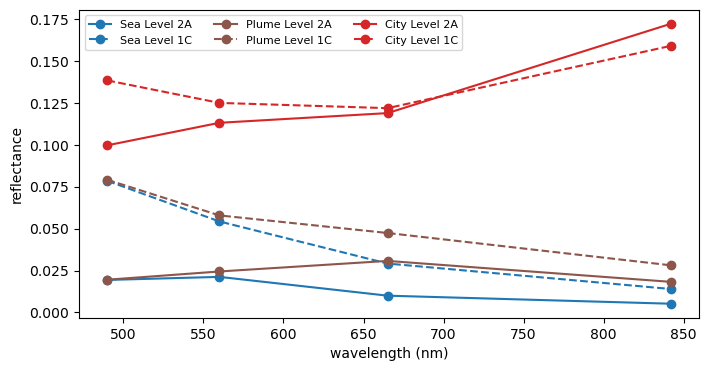

In [37]:
import matplotlib.pyplot as plt

wavelength = [490, 560, 665, 842]
colours = {"Sea": "tab:blue", "Plume": "tab:brown", "City": "tab:red"}

plt.figure(figsize=(8, 4))
for site, (column, row) in sites.items():
    top = [np.nanmean(l1c[band][row:row + 5, column:column + 5]) for band in bands]
    bottom = [np.nanmean(l2a[band][row:row + 5, column:column + 5]) for band in bands]
    plt.plot(wavelength, bottom, marker="o", color=colours[site], label=f"{site} Level 2A")
    plt.plot(wavelength, top, marker="o", linestyle="--", color=colours[site], label=f"{site} Level 1C")

plt.xlabel("wavelength (nm)")
plt.ylabel("reflectance")
plt.legend(ncol=3, fontsize=8)
plt.show()

:::{admonition} Discussion
For which site are the two lines furthest apart, and in which part of the spectrum? Which colour does the atmosphere add the most of, and what does that remind you of from the sky above you?
:::

The numbers tell us that over dark water most of the blue and green light that the satellite measures was added by the air. Whoever uses Level 1C numbers to map turbidity would be mapping the atmosphere. The next step is to remove it ourselves with the simplest method there is.

***
## 3 · Correcting the atmosphere ourselves

### The idea of the dark object

The extra light that the air adds is called **path radiance**. It is light from the sun that was scattered towards the satellite before it ever reached the ground. It is there in every pixel, and it is strongest in blue light, because blue is scattered the most.

Suppose we can find a place in the picture that should be almost black, for example a deep shadow or very clear deep water in the near infrared. Whatever light the satellite measured there must have come from the air. If we subtract that amount from every pixel of the band, we have removed the path radiance. This is called **dark object subtraction**, and it is one of the oldest corrections in remote sensing. We use the version called DOS1.

Nothing in nature is perfectly black, so DOS1 assumes that the dark object reflects 1 percent of the light. The amount we subtract in each band is

$$\text{path} = \rho_\text{dark} - 0.01$$

$$\rho_\text{corrected} = \rho_\text{Level 1C} - \text{path}$$

We find the dark object by looking at the very lowest values of each band in the whole clipped area. Taking the single lowest value would be risky, because one broken pixel could decide everything. So we take a very low percentile instead.

In [38]:
percentile = 0.01    # the darkest 0.01 percent of the pixels in the clipped area
assumed = 0.01       # the reflectance we assume for the dark object, 1 percent

dark = {band: float(np.nanpercentile(l1c[band], percentile)) for band in bands}
path = {band: dark[band] - assumed for band in bands}

table = pd.DataFrame({
    "Dark value (%)": {names[band]: round(dark[band] * 100, 2) for band in bands},
    "Path radiance we subtract (%)": {names[band]: round(path[band] * 100, 2) for band in bands},
})
table

,Dark value (%),Path radiance we subtract (%)
Blue,6.77,5.77
Green,4.36,3.36
Red,2.34,1.34
Near infrared,1.23,0.23


:::{admonition} Discussion
In which band is the dark value largest, and in which is it smallest? Does the order follow what you know about the colour of the sky?
:::

The next cell subtracts the path radiance from every pixel of each band. The table then compares three versions at the three sites, the original Level 1C numbers, our corrected numbers and the Level 2A numbers from ESA.

In [40]:
dos = {band: l1c[band] - path[band] for band in bands}

def block_mean(array, site):
    column, row = sites[site]
    return float(np.nanmean(array[row:row + 5, column:column + 5]))

rows = []
for site in sites:
    for band in bands:
        rows.append({
            "Site": site,
            "Band": names[band],
            "Level 1C (%)": round(block_mean(l1c[band], site) * 100, 1),
            "Our correction (%)": round(block_mean(dos[band], site) * 100, 1),
            "Level 2A (%)": round(block_mean(l2a[band], site) * 100, 1),
        })

pd.DataFrame(rows)

,Site,Band,Level 1C (%),Our correction (%),Level 2A (%)
0,Sea,Blue,7.8,2.1,1.9
1,Sea,Green,5.4,2.1,2.1
2,Sea,Red,2.9,1.6,1.0
3,Sea,Near infrared,1.4,1.2,0.5
4,Plume,Blue,7.9,2.1,2.0
5,Plume,Green,5.8,2.4,2.4
6,Plume,Red,4.7,3.4,3.1
7,Plume,Near infrared,2.8,2.6,1.8
8,City,Blue,13.8,8.1,10.0
9,City,Green,12.5,9.1,11.3


:::{admonition} Discussion
Over the sea, how close does our correction come to Level 2A in blue and green? Over the city, our numbers end up below Level 2A. The correction only subtracts light. What does the real atmosphere also do to the light that comes from the ground, and which part of our method ignores it?
:::

The next cell draws the three versions as spectra, one picture for each site.

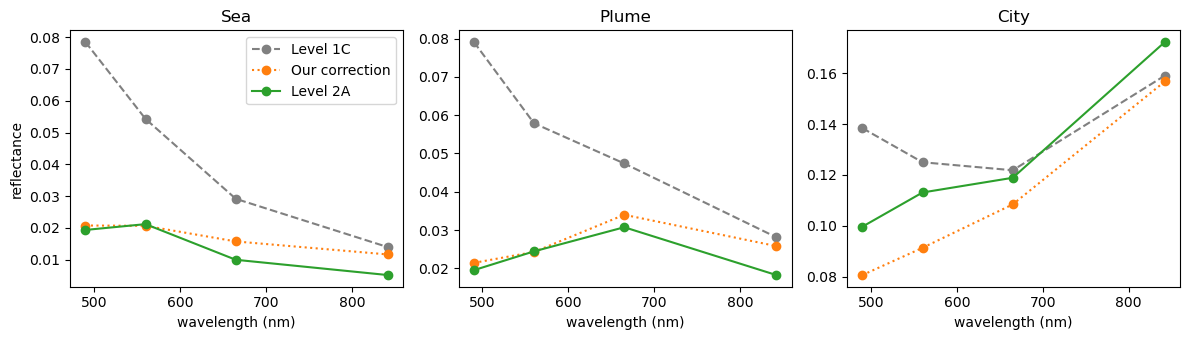

In [41]:
plt.figure(figsize=(12, 3.5))
for number, site in enumerate(sites, start=1):
    plt.subplot(1, 3, number)
    plt.plot(wavelength, [block_mean(l1c[band], site) for band in bands], marker="o", linestyle="--", color="grey", label="Level 1C")
    plt.plot(wavelength, [block_mean(dos[band], site) for band in bands], marker="o", linestyle=":", color="tab:orange", label="Our correction")
    plt.plot(wavelength, [block_mean(l2a[band], site) for band in bands], marker="o", color="tab:green", label="Level 2A")
    plt.title(site)
    plt.xlabel("wavelength (nm)")
    if number == 1:
        plt.ylabel("reflectance")
        plt.legend()
plt.tight_layout()
plt.show()

:::{admonition} Discussion
At which site does the orange line come closest to the green one, and at which is it furthest away? What kind of surface suits this method best?
:::

### How much do our choices matter

We made two choices, the percentile and the 1 percent. The next cell repeats the correction with three different percentiles and prints the blue reflectance of the sea and the ratio of red to green at the plume. The ratio of red to green is the first turbidity measure we will use in the last section. The last row shows the Level 2A values for comparison.

In [42]:
rows = []
for test_percentile in [0.01, 0.1, 1]:
    path_p = {band: float(np.nanpercentile(l1c[band], test_percentile)) - assumed for band in bands}
    blue_sea = block_mean(l1c["B02"], "Sea") - path_p["B02"]
    red_plume = block_mean(l1c["B04"], "Plume") - path_p["B04"]
    green_plume = block_mean(l1c["B03"], "Plume") - path_p["B03"]
    rows.append({
        "Percentile": test_percentile,
        "Sea blue (%)": round(blue_sea * 100, 1),
        "Plume red / green": round(red_plume / green_plume, 2),
    })

rows.append({
    "Percentile": "Level 2A",
    "Sea blue (%)": round(block_mean(l2a["B02"], "Sea") * 100, 1),
    "Plume red / green": round(block_mean(l2a["B04"], "Plume") / block_mean(l2a["B03"], "Plume"), 2),
})

pd.DataFrame(rows)

,Percentile,Sea blue (%),Plume red / green
0,0.01,2.1,1.40
1,0.1,1.8,1.44
2,1,1.5,1.76
3,Level 2A,1.9,1.26


:::{admonition} Discussion
Which of the two numbers is more sensitive to the choice of percentile? If you had to defend one setting to a colleague, how would you do it without a Level 2A product to compare with?
:::

Dark object subtraction is simple, and it needs no knowledge of the sky. It only removes the extra light. The processor that ESA used for Level 2A works different. It estimates how hazy the air was that day and calculates the correction accordingly.

***
## 4 · Aerosol, water vapour and ozone over Vaasa

Our correction subtracted one constant path radiance value per band and used no atmospheric model. The processor that made Level 2A, Sen2Cor, works differently. It estimates three things about the air over each image and calculates the correction from them.

- The **aerosol optical thickness**, called AOT, tells how much haze, smoke and dust the air holds. It is a number without a unit. Around 0.05 is very clean air, around 0.2 is hazy and above 0.5 is thick smoke.
- The **water vapour** tells how much water the whole air column holds. It is given as the depth of water you would get if you condensed all of it, in centimetres.
- The **ozone** tells how much ozone the air holds, in Dobson units. It absorbs some light in the green and red.

Sen2Cor estimates the aerosol from dark vegetation in the image and the water vapour from two near infrared bands, B8A and B09. B09 sits inside an absorption band of water vapour, and B8A sits next to it in a clear window. The more vapour, the darker B09 is compared with B8A. The ozone is not measured by Sentinel-2. It comes from a weather forecast model. The next cell reads what Sen2Cor wrote about this image into the metadata file of the granule.

In [43]:
granule_l2a = glob.glob(f"{data_folder}/{level_2a}/GRANULE/*")[0]
tile_xml = f"{granule_l2a}/MTD_TL.xml"

beliefs = {
    "Aerosol optical thickness, mean over the tile": first(tile_xml, "GRANULE_MEAN_AOT"),
    "How the aerosol was found": first(tile_xml, "AOT_RETRIEVAL_METHOD"),
    "Water vapour, mean over the tile (cm)": first(tile_xml, "GRANULE_MEAN_WV"),
    "Ozone (Dobson units)": first(tile_xml, "OZONE_VALUE"),
    "Where the ozone came from": first(tile_xml, "OZONE_SOURCE"),
}

pd.Series(beliefs, name="Sen2Cor for 21 June 2026")

Aerosol optical thickness, mean over the tile       0.066012
How the aerosol was found                        SEN2COR_DDV
Water vapour, mean over the tile (cm)               1.208194
Ozone (Dobson units)                              331.509841
Where the ozone came from                         AUX_ECMWFT
Name: Sen2Cor for 21 June 2026, dtype: object

:::{admonition} Discussion
Is an aerosol optical thickness of about 0.07 a hazy day or a clean one? Which of the three numbers does Sentinel-2 measure itself, and which comes from somewhere else?
:::

### The aerosol and water vapour layers

Sen2Cor also delivers its estimates as two pictures, one number for each pixel. The layers are called `AOT` and `WVP` and they sit next to the bands in the Level 2A folder. The stored whole numbers are 1000 times the real values, so we divide by 1000. The next function clips a layer to Vaasa the same way as the bands and draws both.

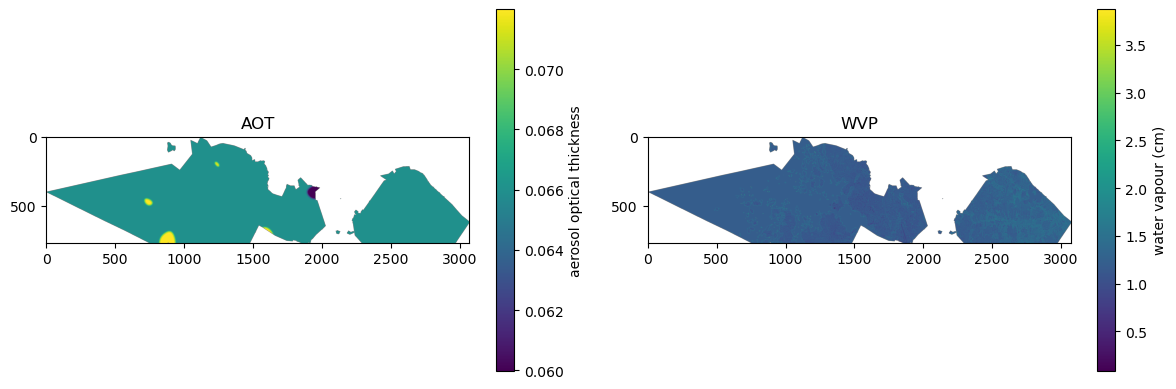

Mean AOT over Vaasa 0.066
Mean water vapour over Vaasa 1.22 cm


In [44]:
def clipped_layer(name):
    file = glob.glob(f"{granule_l2a}/IMG_DATA/R20m/*_{name}_20m.jp2")[0]
    with rasterio.open(file) as src:
        shape = vaasa.to_crs(src.crs).make_valid().iloc[0]
        data, _ = mask(src, [shape], crop=True)
    layer = data[0].astype("float32") / 1000
    layer[data[0] == 0] = np.nan
    return layer

aot = clipped_layer("AOT")
wvp = clipped_layer("WVP")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(aot, cmap="viridis")
plt.colorbar(label="aerosol optical thickness")
plt.title("AOT")

plt.subplot(1, 2, 2)
plt.imshow(wvp, cmap="viridis")
plt.colorbar(label="water vapour (cm)")
plt.title("WVP")

plt.tight_layout()
plt.show()

print("Mean AOT over Vaasa", round(float(np.nanmean(aot)), 3))
print("Mean water vapour over Vaasa", round(float(np.nanmean(wvp)), 2), "cm")

:::{admonition} Discussion
Are the two layers detailed or smooth? What does that tell you about how Sen2Cor treats the atmosphere over a small area like Vaasa? A model of the Copernicus atmosphere service gave about 0.04 for the same hour. How does that compare with the number above, and what does the difference say about how certain the correction can be?
:::

### The bands that measure the air

Some Sentinel-2 bands are not meant for pictures of the ground. They are there to measure the atmosphere.

| Band | Wavelength | What it is used for |
|---|---|---|
| B01 | 443 nm | Very short wavelength light, very sensitive to aerosol |
| B8A | 865 nm | Near infrared in a clear window, the reference for water vapour |
| B09 | 945 nm | Inside a water vapour absorption band, darker when the air is humid |
| B10 | 1375 nm | Strongly absorbed by water vapour, so the ground stays hidden and only thin high cirrus shows up |

B10 exists in the Level 1C product only. Thin cirrus is a risk for turbidity, because a white veil over dark water raises the red and the green light and looks like muddy water.

We have now seen three versions of the same view, the raw one, our own correction and ESA's physical one. In the last section we calculate turbidity from each and see how much the correction matters for the map.

***
## 5 · Turbidity

Turbidity is the cloudiness of water. It comes from particles such as clay, algae and organic matter that scatter light. The more particles there are, the more light the water sends back, and the effect is strongest in the red. Clear water absorbs red light almost completely, so red light coming out of the water is a sign of particles.

We use two simple algorithms on the red and green bands that we already have.

**The red/green ratio** divides the red reflectance by the green reflectance. It has no coefficients and no unit. It shows where the water is more or less turbid and gives no value in FNU.

$$\text{ratio} = \frac{\rho_\text{red}}{\rho_\text{green}}$$

**The single band formula of Nechad** turns the red reflectance directly into turbidity in FNU, the Formazin Nephelometric Unit that water laboratories use. It was fitted to measurements in coastal waters. The two coefficients below belong to the red band at 665 nm.

$$T = \frac{A \, \rho_\text{red}}{1 - \rho_\text{red} / C} \qquad A = 289.29 \text{ FNU} \qquad C = 0.1686$$

Both algorithms expect the reflectance of the water itself. The three versions of our picture disagree about exactly that, so the same algorithm should give four different maps.

### Clipping out the land

We want to map water and nothing else. The Level 2A product carries a scene classification layer called SCL at 20 m pixel size. Class 6 means water. We use this one mask for all three versions, so that the maps differ only because of the atmosphere. The next cell clips the layer to Vaasa, makes its pixels 10 m and tells how much of the area is water.

In [16]:
scl_file = glob.glob(f"{granule_l2a}/IMG_DATA/R20m/*_SCL_20m.jp2")[0]
with rasterio.open(scl_file) as src:
    shape = vaasa.to_crs(src.crs).make_valid().iloc[0]
    scl_data, _ = mask(src, [shape], crop=True)

scl = np.repeat(np.repeat(scl_data[0], 2, axis=0), 2, axis=1)    # 20 m pixels become 10 m pixels

water = np.zeros(l2a["B04"].shape, dtype=bool)
height = min(scl.shape[0], water.shape[0])
width = min(scl.shape[1], water.shape[1])
water[:height, :width] = scl[:height, :width] == 6

inside = np.isfinite(l2a["B04"])
print("Pixels inside the Vaasa polygon", int(inside.sum()))
print("Pixels classified as water", int((water & inside).sum()))
print("Share of the area that is water (%)", round(float((water & inside).sum() / inside.sum() * 100), 1))

Pixels inside the Vaasa polygon 4802827
Pixels classified as water 1951010
Share of the area that is water (%) 40.6


:::{admonition} Discussion
Water is only part of the municipality. Why do we leave the land out, and what would the red/green ratio mean on a forest or a field?
:::

### Yet another atmospheric correction algorithm, C2RCC

Sen2Cor was written for land. It looks for dark vegetation to find the aerosol and then applies what it found to the whole image, water included. A processor called **C2RCC** was written for water. It uses neural networks that were trained on simulated light in the air and in the water, and it also estimates what is in the water. The Finnish Environment Institute uses it for the Tarkka service.

C2RCC runs in the program SNAP and needs a lot of memory. It was run beforehand on CSC for the Level 1C product and the result for Vaasa was saved as one GeoTIFF with 11 bands. The bands are the remote sensing reflectance in four bands, five properties of the water and the particles in it, the attenuation of blue light and a flag band. The next cell reads them and clips them to Vaasa like the other bands.

The remote sensing reflectance is the water leaving light divided by the light that falls on the water. It is given per steradian and we multiply it by $\pi$ to get a reflectance that can be compared with the other versions.

C2RCC also turns the particle and pigment properties into two concentrations with fixed formulas.

$$b_\text{tot} = b_\text{part} + b_\text{wit} \qquad \text{TSM} = 1.06 \, b_\text{tot}^{0.942} \qquad \text{CHL} = 21.0 \, a_\text{pig}^{1.04}$$

TSM is the total suspended matter in grams per cubic metre and CHL is the chlorophyll in milligrams per cubic metre.

In [45]:
c2rcc_file = f"{data_folder}/c2rcc/c2rcc_vaasa.tif"
c2rcc_order = ["rrs_B2", "rrs_B3", "rrs_B4", "rrs_B5", "iop_apig", "iop_adet", "iop_agelb",
               "iop_bpart", "iop_bwit", "kd489", "c2rcc_flags"]

with rasterio.open(c2rcc_file) as src:
    shape = vaasa.to_crs(src.crs).make_valid().iloc[0]
    cube, _ = mask(src, [shape], crop=True)

def fit(layer):
    out = np.full(l2a["B04"].shape, np.nan, dtype="float32")
    height = min(layer.shape[0], out.shape[0])
    width = min(layer.shape[1], out.shape[1])
    out[:height, :width] = layer[:height, :width]
    out[out == 0] = np.nan
    return out

c2rcc = {name: fit(cube[number]) for number, name in enumerate(c2rcc_order)}
c2rcc["conc_tsm"] = 1.06 * (c2rcc["iop_bpart"] + c2rcc["iop_bwit"]) ** 0.942
c2rcc["conc_chl"] = c2rcc["iop_apig"] ** 1.04 * 21.0

c2rcc_refl = {band: np.pi * c2rcc[f"rrs_B{number}"] for band, number in [("B02", 2), ("B03", 3), ("B04", 4)]}

print("Shape of the C2RCC clip", cube.shape[1:], "and of the Level 2A clip", l2a["B04"].shape)
print("Pixels with a C2RCC value", int(np.isfinite(c2rcc["rrs_B4"]).sum()))

Shape of the C2RCC clip (1537, 6140) and of the Level 2A clip (1537, 6140)
Pixels with a C2RCC value 2009276


:::{admonition} Discussion
The two clips should have almost the same shape. Why is that important before we compare pixel by pixel? C2RCC gives values only where its own validity test passes. What kind of pixels could it leave out?
:::

### The algorithms on three versions

The next cell applies both algorithms to the Level 1C numbers, to our corrected numbers, to the Level 2A numbers and to the C2RCC numbers. Pixels that are not water, and pixels where the red reflectance is zero or below, become missing values.

In [46]:
A_nechad, C_nechad = 289.29, 0.1686     # Nechad et al. 2010, red band at 665 nm, turbidity in FNU

versions = {"Level 1C": l1c, "Our correction": dos, "Level 2A": l2a, "C2RCC": c2rcc_refl}

def red_green(refl):
    red, green = refl["B04"], refl["B03"]
    with np.errstate(divide="ignore", invalid="ignore"):
        good = water & (red > 0) & (green > 0)
        return np.where(good, red / green, np.nan)

def nechad(red):
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(water & (red > 0), A_nechad * red / (1 - red / C_nechad), np.nan)

ratio_maps = {name: red_green(refl) for name, refl in versions.items()}
turbidity_maps = {name: nechad(refl["B04"]) for name, refl in versions.items()}

summary = []
for name in versions:
    summary.append({
        "Version": name,
        "Water pixels with a value": int(np.isfinite(turbidity_maps[name]).sum()),
        "Median red / green": round(float(np.nanmedian(ratio_maps[name])), 2),
        "Median turbidity (FNU)": round(float(np.nanmedian(turbidity_maps[name])), 1),
        "90th percentile turbidity (FNU)": round(float(np.nanpercentile(turbidity_maps[name], 90)), 1),
    })

pd.DataFrame(summary)

,Version,Water pixels with a value,Median red / green,Median turbidity (FNU),90th percentile turbidity (FNU)
0,Level 1C,1951010,0.57,11.6,14.2
1,Our correction,1951010,0.82,6.2,8.4
2,Level 2A,1951010,0.56,4.3,6.6
3,C2RCC,1934402,0.45,2.1,3.7


:::{admonition} Discussion
Look at the medians over all the water of Vaasa. Which version gives the highest turbidity and which the lowest? Does the order follow what you learned about the atmosphere in the earlier sections?
:::

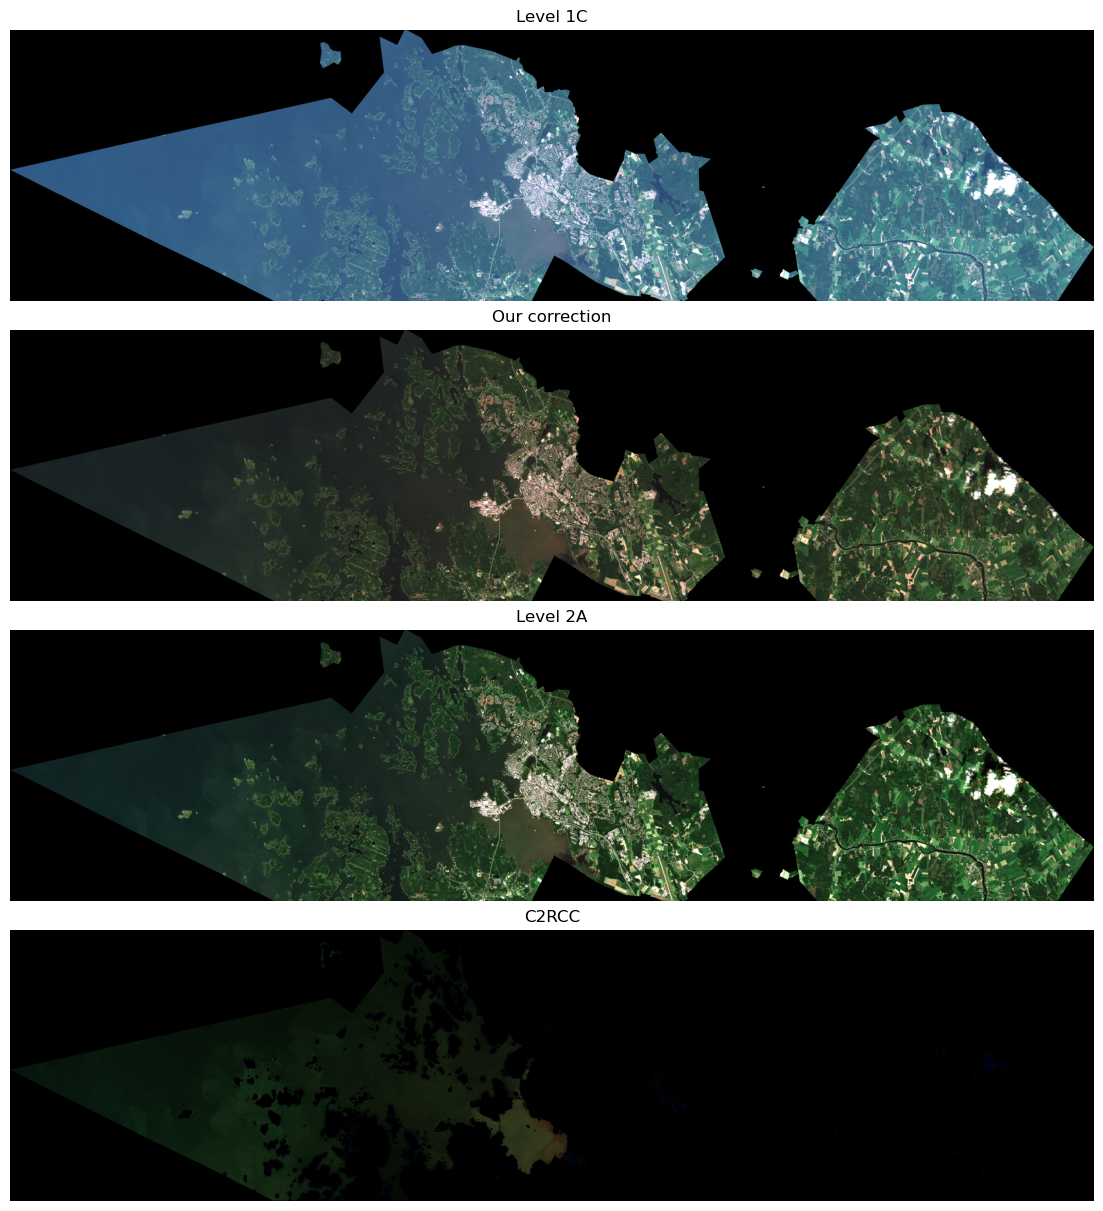

In [47]:
fig, axes = plt.subplots(4, 1, figsize=(12, 12), constrained_layout=True)
for axis, (name, refl) in zip(axes, versions.items()):
    rgb = np.dstack([refl["B04"], refl["B03"], refl["B02"]])
    rgb = np.nan_to_num(rgb / 0.15).clip(0, 1)
    axis.imshow(rgb)
    axis.set_title(name)
    axis.set_axis_off()
plt.show()

### The turbidity maps

The next cell draws the Nechad turbidity for the four versions on one colour scale. The scale is set by the Level 2A values. Anything above its 99th percentile has the same colour. Land is grey.

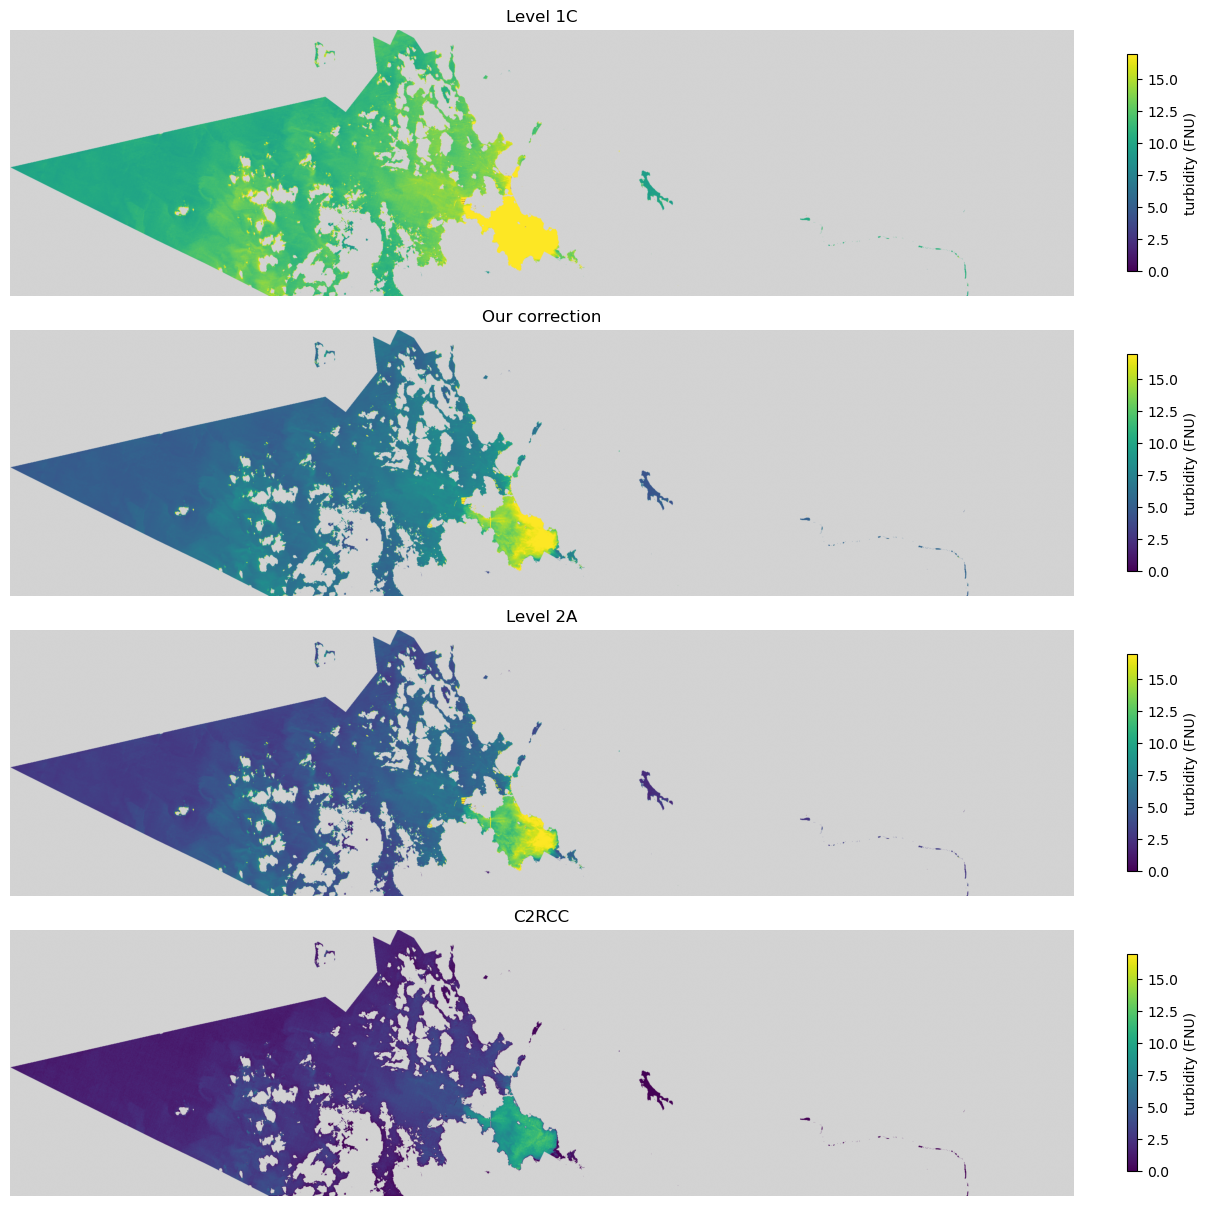

In [19]:
import copy

cmap = copy.copy(plt.get_cmap("viridis"))
cmap.set_bad("lightgrey")

top = float(np.nanpercentile(turbidity_maps["Level 2A"], 99))

fig, axes = plt.subplots(4, 1, figsize=(12, 12), constrained_layout=True)
for axis, (name, array) in zip(axes, turbidity_maps.items()):
    picture = axis.imshow(array, cmap=cmap, vmin=0, vmax=top)
    axis.set_title(name)
    axis.set_axis_off()
    fig.colorbar(picture, ax=axis, label="turbidity (FNU)", shrink=0.8)
plt.show()

:::{admonition} Discussion
Compare the four maps. Where is the water most turbid in all of them? Where do they disagree the most, and is it in the pattern or in the level? Which of the four maps would you give to the harbour authority, and what would you tell them about the others?
:::

The same comparison for the red/green ratio. This time the colour scale runs from the 2nd to the 98th percentile of the Level 2A ratio.

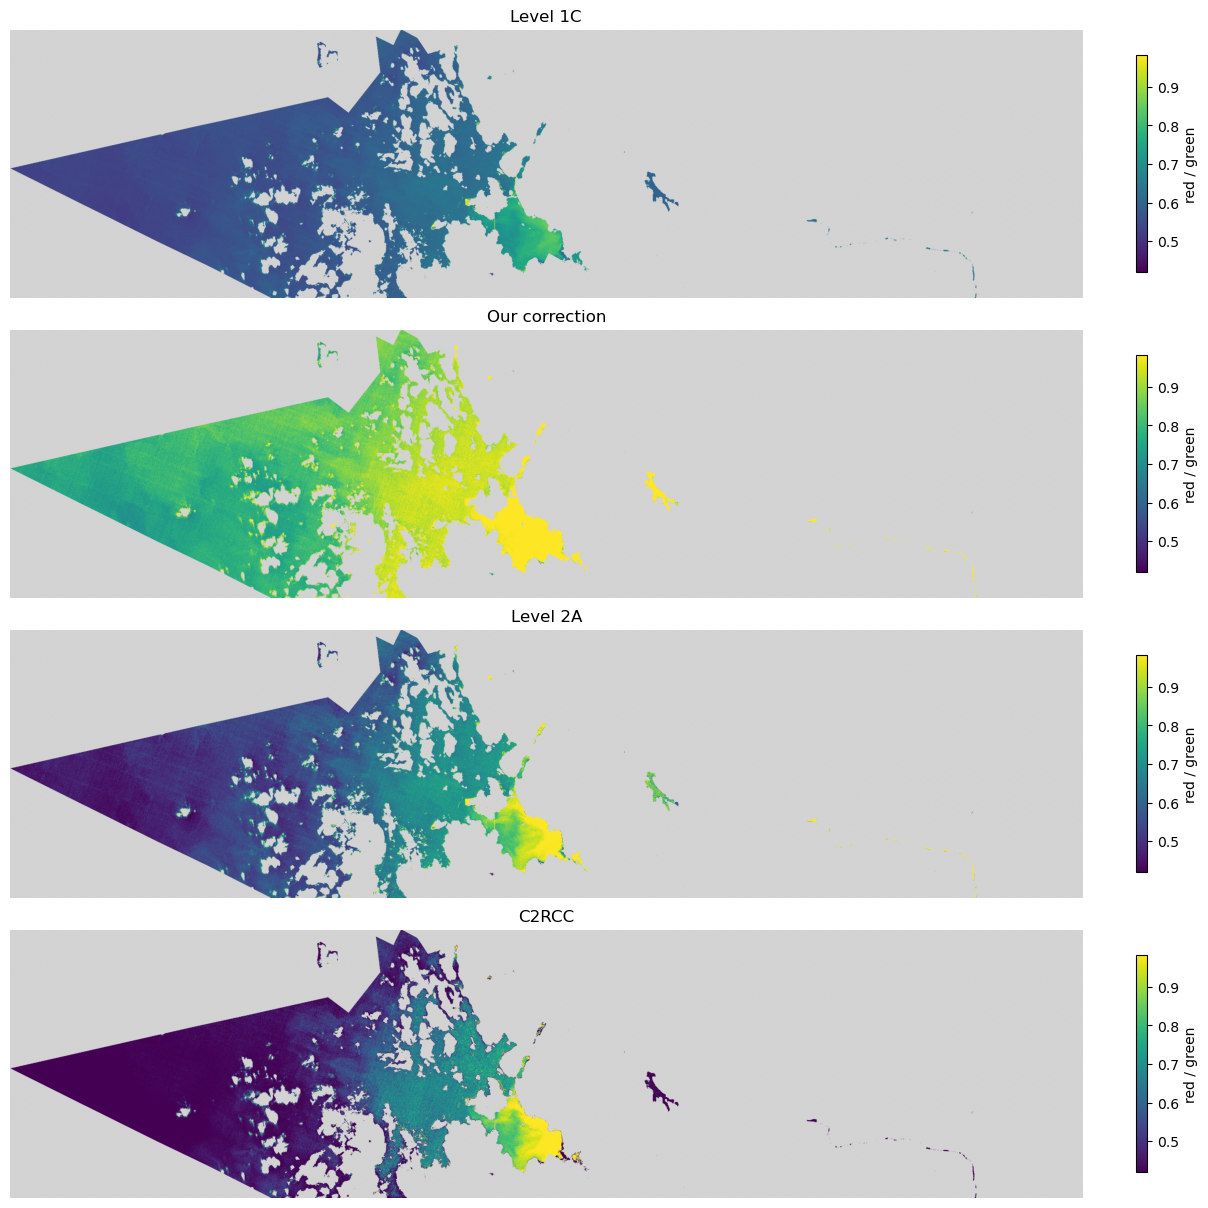

In [20]:
low = float(np.nanpercentile(ratio_maps["Level 2A"], 2))
high = float(np.nanpercentile(ratio_maps["Level 2A"], 98))

fig, axes = plt.subplots(4, 1, figsize=(12, 12), constrained_layout=True)
for axis, (name, array) in zip(axes, ratio_maps.items()):
    picture = axis.imshow(array, cmap=cmap, vmin=low, vmax=high)
    axis.set_title(name)
    axis.set_axis_off()
    fig.colorbar(picture, ax=axis, label="red / green", shrink=0.8)
plt.show()

:::{admonition} Discussion
The ratio has no unit and the colour scale is the same for all four maps. Which version stands out from the others, and in what way? Our correction subtracts a different amount from each band. What does that do to a ratio of two bands, and does the open sea still look like clear water?
:::

### Sea and plume

The maps are large, so the next cell goes back to the sea and the plume and reads the 5 by 5 blocks again. The reflectance is averaged first and the algorithms are applied to the averages, in the same way as the ratio in the percentile test of section 3. The last column tells how many times more turbid the plume is than the sea.

In [48]:
rows = []
contrast = {}
for name, refl in versions.items():
    values = {}
    for site in ["Sea", "Plume"]:
        red = block_mean(refl["B04"], site)
        green = block_mean(refl["B03"], site)
        values[site] = {
            "ratio": red / green,
            "turbidity": A_nechad * red / (1 - red / C_nechad),
        }
    contrast[name] = values["Plume"]["turbidity"] / values["Sea"]["turbidity"]
    for site in ["Sea", "Plume"]:
        rows.append({
            "Version": name,
            "Site": site,
            "Red / green": round(values[site]["ratio"], 2),
            "Turbidity (FNU)": round(values[site]["turbidity"], 1),
            "Plume / sea turbidity": round(contrast[name], 1) if site == "Plume" else "",
        })

pd.DataFrame(rows)

,Version,Site,Red / green,Turbidity (FNU),Plume / sea turbidity
0,Level 1C,Sea,0.54,10.2,
1,Level 1C,Plume,0.82,19.1,1.9
2,Our correction,Sea,0.76,5.0,
3,Our correction,Plume,1.40,12.3,2.4
4,Level 2A,Sea,0.47,3.1,
5,Level 2A,Plume,1.26,10.9,3.5
6,C2RCC,Sea,0.37,1.6,
7,C2RCC,Plume,2.05,9.1,5.6


:::{admonition} Discussion
Which version keeps the contrast between the plume and the sea, and which one flattens it? A user who only wants to know where the water is dirtier than elsewhere and a user who needs a number in FNU need different things from the atmospheric correction. Which of the two can live with Level 1C?
:::

### What C2RCC says about the particles

C2RCC gives its own estimate of the total suspended matter in grams per cubic metre. This is a different quantity from turbidity in FNU, because turbidity depends on how the particles scatter light and TSM counts their mass. Both should still rise and fall together. The next cell reads the TSM at the two places and then checks, over thousands of water pixels, whether the Nechad turbidity from Level 2A and the TSM from C2RCC put the pixels in the same order.

TSM at the sea (g/m3) 2.6
TSM at the plume (g/m3) 32.2


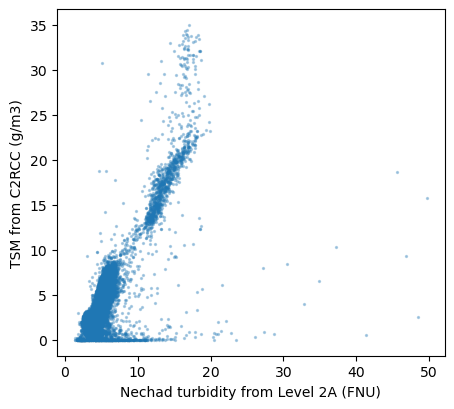

Correlation between the two rankings 0.73


In [49]:
tsm = np.where(water, c2rcc["conc_tsm"], np.nan)

print("TSM at the sea (g/m3)", round(block_mean(tsm, "Sea"), 1))
print("TSM at the plume (g/m3)", round(block_mean(tsm, "Plume"), 1))

both = np.isfinite(tsm) & np.isfinite(turbidity_maps["Level 2A"])
picks = np.random.default_rng(1).choice(np.flatnonzero(both), size=min(20000, int(both.sum())), replace=False)
x = turbidity_maps["Level 2A"].ravel()[picks]
y = tsm.ravel()[picks]

plt.figure(figsize=(5, 4.5))
plt.scatter(x, y, s=2, alpha=0.3)
plt.xlabel("Nechad turbidity from Level 2A (FNU)")
plt.ylabel("TSM from C2RCC (g/m3)")
plt.show()

rank_correlation = pd.Series(x).rank().corr(pd.Series(y).rank())
print("Correlation between the two rankings", round(float(rank_correlation), 2))

:::{admonition} Discussion
Do the two independent processors agree on which water is muddier? Where on the scatter plot do they disagree the most? Which quantity would a swimmer, a harbour authority and a lake researcher each ask for?
:::

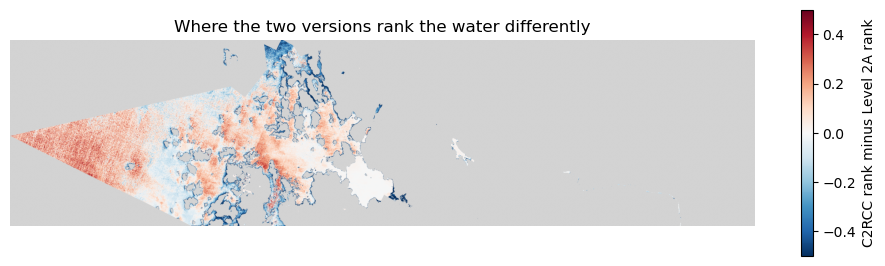

Share of water pixels where the ranks differ by more than a quarter 2.9 percent


In [50]:
import copy

both = np.isfinite(tsm) & np.isfinite(turbidity_maps["Level 2A"])

def percentile_rank(array):
    rank = np.full(array.shape, np.nan)
    rank[both] = pd.Series(array[both]).rank(pct=True).to_numpy()
    return rank

difference = percentile_rank(tsm) - percentile_rank(turbidity_maps["Level 2A"])

cmap_difference = copy.copy(plt.get_cmap("RdBu_r"))
cmap_difference.set_bad("lightgrey")

plt.figure(figsize=(12, 4))
picture = plt.imshow(difference, cmap=cmap_difference, vmin=-0.5, vmax=0.5)
plt.colorbar(picture, label="C2RCC rank minus Level 2A rank", shrink=0.8)
plt.title("Where the two versions rank the water differently")
plt.axis("off")
plt.show()

print("Share of water pixels where the ranks differ by more than a quarter", round(float(np.nanmean(np.abs(difference) > 0.25)) * 100, 1), "percent")

### What we found

The atmosphere adds a layer of light on top of the water signal, and over dark water that layer is as large as the signal. A turbidity algorithm cannot tell the difference, so it reports the air as muddy water. Our simple dark object correction removes much of this, and the physical correction of Level 2A removes more of it with the help of what the processor knows about the sky. A processor built for water, C2RCC, gives a fourth answer from the same Level 1C product. The turbidity values depend on the version you choose, so a number in FNU should always come with the name of the processing behind it.

In [57]:
import urllib.request
from rasterio.warp import reproject, Resampling

date = level_2a.split("_")[2][:8]
date = f"{date[:4]}-{date[4:6]}-{date[6:]}"
minx, miny, maxx, maxy = vaasa.to_crs(3067).total_bounds

url = ("https://geoserver2.ymparisto.fi/geoserver/eo/wcs?service=WCS&version=2.0.1&request=GetCoverage"
       "&coverageId=eo__EO_HR_WQ_S2_TURB&format=image/tiff"
       f"&subset=E({minx},{maxx})&subset=N({miny},{maxy})&subset=time(%22{date}T00:00:00.000Z%22)")
os.makedirs("data/tarkka", exist_ok=True)
tarkka_file = f"data/tarkka/tarkka_turbidity_{date}.tif"
urllib.request.urlretrieve(url, tarkka_file)

with rasterio.open(tarkka_file) as src:
    tarkka = src.read(1)
    tarkka[tarkka == 0] = np.nan
    tarkka_transform, tarkka_crs = src.transform, src.crs

granule = glob.glob(f"{os.path.join(data_folder, level_2a)}/GRANULE/*")[0]
red_file = glob.glob(f"{granule}/IMG_DATA/R10m/*_B04_10m.jp2")[0]
with rasterio.open(tarkka_file) as src:
    shape = vaasa.to_crs(src.crs).make_valid().iloc[0]
    clipped, tarkka_transform = mask(src, [shape], crop=True)
    tarkka = clipped[0]
    tarkka[tarkka == 0] = np.nan
    tarkka_crs = src.crs

def on_tarkka_grid(array):
    out = np.full(tarkka.shape, np.nan, dtype="float32")
    reproject(array.astype("float32"), out, src_transform=our_transform, src_crs=our_crs, src_nodata=np.nan,
              dst_transform=tarkka_transform, dst_crs=tarkka_crs, dst_nodata=np.nan, resampling=Resampling.average)
    return out

print("Date of the Tarkka data", date)
print("Pixels with a Tarkka value", int(np.isfinite(tarkka).sum()))

Date of the Tarkka data 2026-06-21
Pixels with a Tarkka value 44759


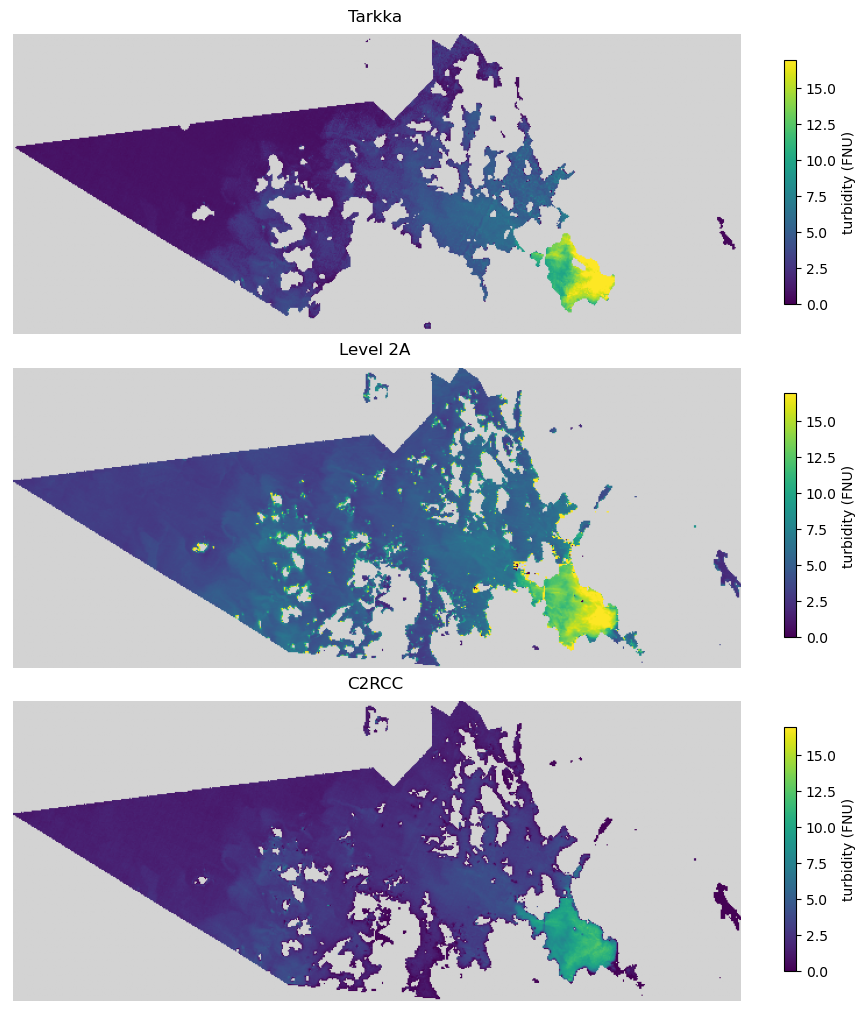

In [59]:
top = float(np.nanpercentile(tarkka, 99))
panels = {"Tarkka": tarkka,
          "Level 2A": on_tarkka_grid(turbidity_maps["Level 2A"]),
          "C2RCC": on_tarkka_grid(turbidity_maps["C2RCC"])}

rows, columns = np.where(np.isfinite(tarkka))
margin = 5

fig, axes = plt.subplots(3, 1, figsize=(10, 10), constrained_layout=True)
for axis, (name, array) in zip(axes, panels.items()):
    picture = axis.imshow(array, cmap=cmap, vmin=0, vmax=top)
    axis.set_xlim(columns.min() - margin, columns.max() + margin)
    axis.set_ylim(rows.max() + margin, rows.min() - margin)
    axis.set_title(name)
    axis.set_axis_off()
    fig.colorbar(picture, ax=axis, label="turbidity (FNU)", shrink=0.8)
plt.show()